# EnrichMap for single-cell resolution data

This tutorial demonstrates how to use `EnrichMap` with single-cell resolution spatial data, using a Xenium section of human breast cancer ([Janesick et al., 2023](https://www.nature.com/articles/s41467-023-43458-x)).

Spot-based data such as Visium sit on a regular grid, so a fixed number of nearest neighbours (6 by default) describes each spot's neighbourhood well. Cells are not on a grid: their density varies across the tissue. For single-cell data, `EnrichMap` can therefore build the smoothing neighbourhood from a Delaunay triangulation of the cell centroids, which adapts to local cell density.

For a detailed introduction to scoring, spatial diagnostics and gene contributions, see [EnrichMap tutorial for one sample](one_sample.ipynb).

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

Import required packages.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import squidpy as sq
from sklearn.metrics import roc_auc_score

import enrichmap as em

sc.set_figure_params(frameon=False)
plt.rcParams["axes.grid"] = False

Read in the dataset. Each cell carries its centroid in `adata.obsm["spatial"]` and the cell type annotations of Janesick et al. in `adata.obs["Cluster"]`.

In [3]:
adata = sc.read(
    "xenium_breast.h5ad",
    backup_url="https://zenodo.org/records/15438169/files/xenium_aligned_ductal_invasive.h5ad?download=1",
)

The dataset is already shared with normalised counts. So, let's have a look at the cell type annotations.

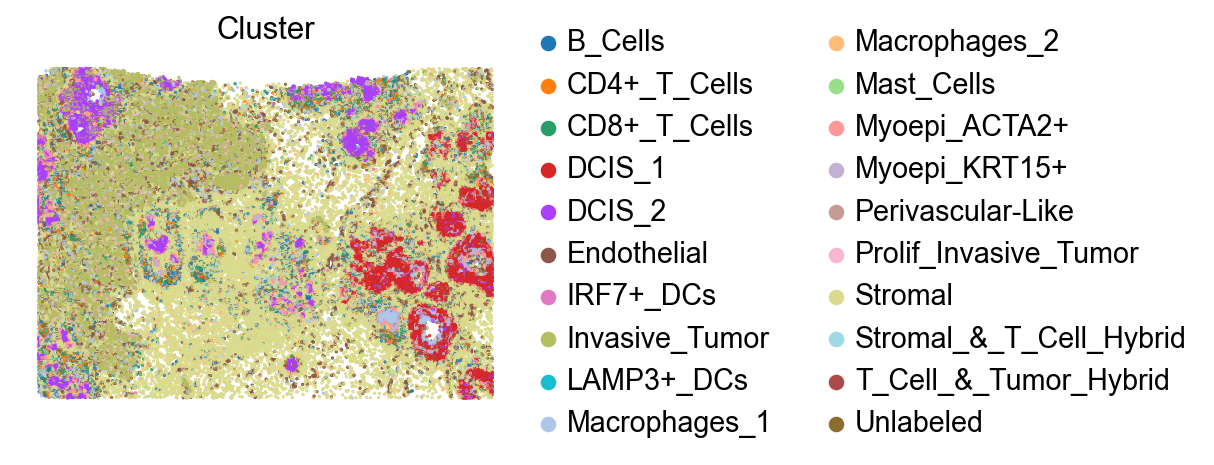

In [4]:
sq.pl.spatial_scatter(adata, color="Cluster", shape=None, size=0.5)

We score two cell populations: ductal carcinoma *in situ* (DCIS) and CD8$^+$ T cells. Each signature holds the ten genes most up-regulated in the population against all other cells, from a pseudo-bulk differential expression analysis.

In [5]:
signature_dict = {
    "DCIS": ["CEACAM6", "AGR3", "CEACAM8", "SCGB2A1", "ESR1", "SERPINA3", "TACSTD2", "CLDN4", "HPX", "S100A14"],
    "CD8_T_cells": ["CD8A", "CD8B", "CD3D", "CD3E", "CD3G", "TRAC", "NKG7", "GZMA", "CCL5", "PRF1"],
}

## Scoring on a Delaunay graph

With `delaunay=True`, the neighbours of each cell are the cells it shares an edge with in the Delaunay triangulation of the centroids; `n_neighbors` is then ignored. `n_rings` sets how many graph hops are included in the smoothing neighbourhood: `n_rings=2` adds the neighbours of neighbours, about 20 cells per cell.

As in the other tutorials, each smoothed score is standardised against matched random gene sets (the null model, on by default), so a positive score means the signature scores above random genes of similar expression level and variability at that cell.

In [6]:
em.tl.score(
    adata,
    gene_set=signature_dict,
    delaunay=True,
    n_rings=2,
)

Scoring CD8_T_cells: 10/10 genes found: 100%|██████████| 2/2 [00:00<00:00, 13.60it/s]


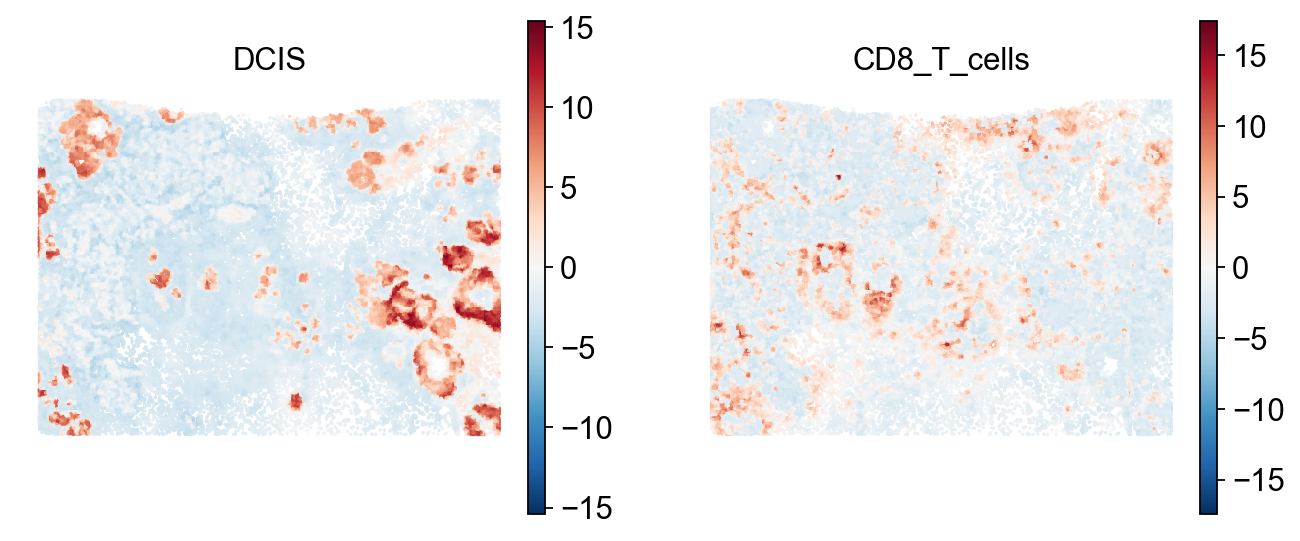

In [7]:
em.pl.spatial_enrichmap(
    adata,
    score_key=["DCIS_score", "CD8_T_cells_score"],
    shape=None,
    size=0.5,
)

## Calling enriched cells

To call cells rather than rank them, set `compute_q_vals=True`. Each cell then receives an empirical *p* value against its matched random gene sets and a Benjamini–Hochberg *q* value, stored in `adata.obs` as `<signature>_q`. *q* values use 1,000 control sets by default, because the smallest attainable *p* value is 1 / (number of control sets + 1).

In [8]:
em.tl.score(
    adata,
    gene_set=signature_dict,
    delaunay=True,
    n_rings=2,
    compute_q_vals=True,
)

Scoring CD8_T_cells: 10/10 genes found: 100%|██████████| 2/2 [00:00<00:00, 11.28it/s]


With `plot_fdr=True`, cells at *q* < 0.05 are outlined in black.

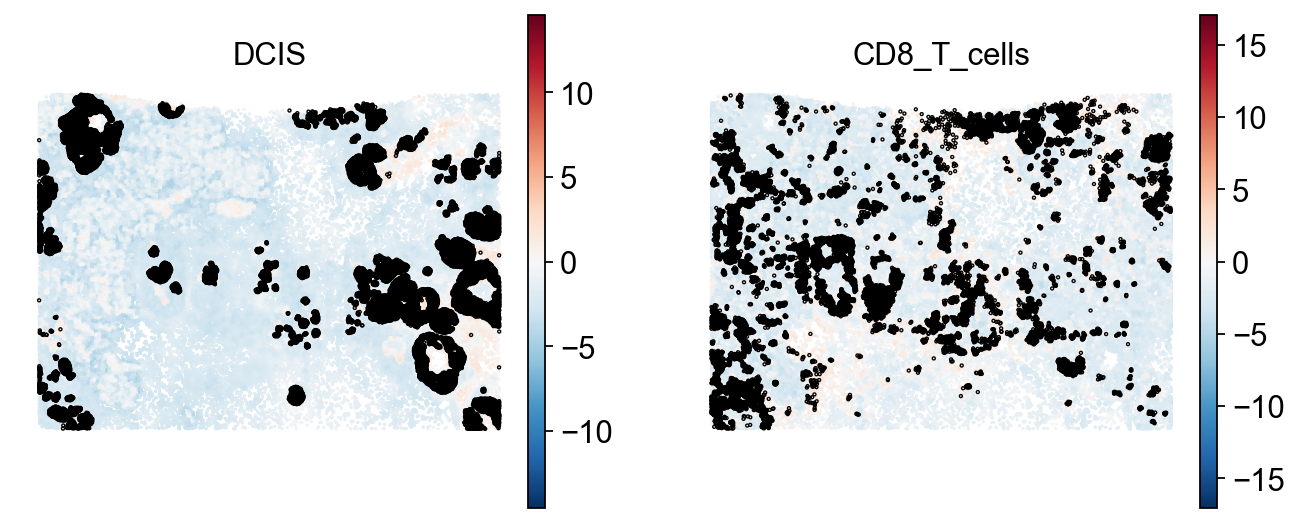

In [9]:
em.pl.spatial_enrichmap(
    adata,
    score_key=["DCIS_score", "CD8_T_cells_score"],
    shape=None,
    size=0.5,
    plot_fdr=True,
)

In [10]:
(adata.obs[["DCIS_q", "CD8_T_cells_q"]] < 0.05).sum()

DCIS_q           28794
CD8_T_cells_q    19583
dtype: int64

## Agreement with the cell type annotations

We can check how well each score separates the annotated cells from all other cells.

In [11]:
targets = {
    "DCIS": adata.obs["Cluster"].isin(["DCIS_1", "DCIS_2"]),
    "CD8_T_cells": adata.obs["Cluster"] == "CD8+_T_Cells",
}

for signature, is_target in targets.items():
    adata.obs[f"{signature}_group"] = np.where(is_target, signature, "Rest")
    auc = roc_auc_score(is_target, adata.obs[f"{signature}_score"])
    print(f"{signature}: AUROC = {auc:.3f}")

DCIS: AUROC = 0.976
CD8_T_cells: AUROC = 0.831


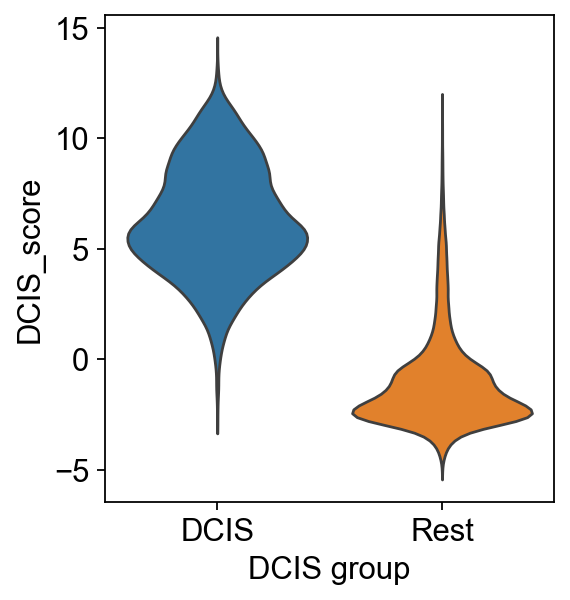

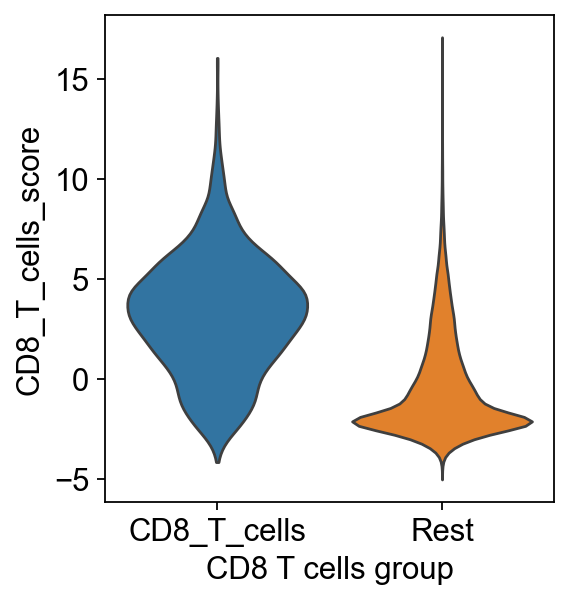

In [12]:
sc.pl.violin(adata, keys="DCIS_score", groupby="DCIS_group", stripplot=False)
sc.pl.violin(adata, keys="CD8_T_cells_score", groupby="CD8_T_cells_group", stripplot=False)